# Avance 1 – Proyecto Integrador DATA STARTUP
## Predicción de demanda diaria de la taquería (Definición del problema + EDA)

**Materias:** Cómputo en la Nube (IAD-2408) x Analítica (IAD-2403)

**Cliente:** Taquería familiar (guisados, aguas y refrescos)

**Equipo:** Jukari Molinero De la Cruz, Diego Armando Torres Flores

---
## 1. Definición del problema

### 1.1 Contexto
La dueña Rocio De la Cruz, decide cuánto cocinar y cuánta tortilla comprar **por experiencia**: ella estima cuántos tacos va a vender y de ahí calcula los kilos de tortilla, aunque casi no hay merma de comida, un error de estimación significa quedarse sin producto que seria venta perdida o comprar de más. Ella misma dijo que le gustaría **saber cuánta comida venderá**

### 1.2 Variable objetivo
- **Variable objetivo:** `cantidad_vendida` = número de piezas vendidas de un producto (guisado o bebida) en un día
- **Tipo de problema:** **Regresión** (la variable es numérica discreta, de conteo, entre 0 y 20 en los datos actuales)
- Un nivel de agregación alternativo (para etapas posteriores) es la **demanda total diaria** de tacos

### 1.3 Justificación y valor práctico
| Pregunta | Respuesta |
|---|---|
| ¿Quién usa la predicción? | Rocio cada mañana, decide cuánto guisado preparar y cuánta tortilla comprar|
| ¿Qué decisión mejora? | Compras y preparación diaria, hoy basadas solo en intuición|
| ¿Qué se gana? | Menos faltantes de los guisados más vendidos y menos sobrante de los de baja rotación|
| ¿Cómo se mide el éxito? | Error de predicción (MAE/RMSE) menor que el de una regla simple, como el promedio histórico del producto|

> **Nota de honestidad:** los datos son **sintéticos**, calibrados con la entrevista a la dueña, porque la taquería no lleva un registro de ventas. Las conclusiones del EDA describen el comportamiento *simulado*; deben validarse con datos reales cuando existan.


## 2. Carga del dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

# utf-8-sig porque el CSV trae BOM al inicio
df = pd.read_csv('ventas_tacos_8_semanas.csv', encoding='utf-8-sig')
df = df.rename(columns={'Fecha':'fecha','Guisado o bebida':'producto','Cantidad vendida':'cantidad_vendida',
                        'Precio unitario (MXN)':'precio_unitario','Total vendido (MXN)':'total_vendido',
                        'Llovió':'llovio','Disponible':'disponible'})
df['fecha'] = pd.to_datetime(df['fecha'])
df.head(10)

,fecha,producto,cantidad_vendida,precio_unitario,total_vendido,llovio,disponible
0,2026-09-01,Agua del día,15,15,225,1,1
1,2026-09-01,Chicharrón,10,15,150,1,1
2,2026-09-01,Frijoles,4,15,60,1,1
3,2026-09-01,Huevo con jamón,13,15,195,1,1
4,2026-09-01,Lengua,4,15,60,1,1
5,2026-09-01,Machaca,5,15,75,1,1
6,2026-09-01,Pepena,3,15,45,1,1
7,2026-09-01,Pollo con crema,15,15,225,1,1
8,2026-09-01,Pollo en salsa verde,18,15,270,1,1
9,2026-09-01,Puerco con calabacitas,7,15,105,1,1


In [2]:
print('Filas, columnas:', df.shape)
print('Rango de fechas:', df['fecha'].min().date(), '->', df['fecha'].max().date(), f"({df['fecha'].nunique()} días)")
print('Productos distintos:', df['producto'].nunique())
df.info()

Filas, columnas: (672, 7)
Rango de fechas: 2026-09-01 -> 2026-10-26 (56 días)
Productos distintos: 12
<class 'pandas.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   fecha             672 non-null    datetime64[us]
 1   producto          672 non-null    str           
 2   cantidad_vendida  672 non-null    int64         
 3   precio_unitario   672 non-null    int64         
 4   total_vendido     672 non-null    int64         
 5   llovio            672 non-null    int64         
 6   disponible        672 non-null    int64         
dtypes: datetime64[us](1), int64(5), str(1)
memory usage: 36.9 KB


### 2.1 Ingeniería de variables
El CSV trae 7 columnas (fecha, producto, cantidad, precio, total, llovió, disponible), y `total_vendido` es `cantidad × precio` (sería *fuga de información* usarla para predecir). Además, se derivan de la **fecha** y del **producto** los factores que la dueña mencionó en la entrevista (día de la semana, quincena, fin de semana).

In [3]:
df['dia_semana_num'] = df['fecha'].dt.dayofweek          # 0=lunes ... 6=domingo
df['dia_semana']     = df['fecha'].dt.day_name()
df['dia_mes']        = df['fecha'].dt.day
df['semana_mes']     = (df['fecha'].dt.day - 1) // 7 + 1
df['es_fin_semana']  = (df['dia_semana_num'] >= 5).astype(int)
# Quincena: la dueña dice que se vende más en quincena (días 15 y 30). Se marca el día de pago y el siguiente.
df['es_quincena']    = df['dia_mes'].isin([15, 16, 30, 31, 1]).astype(int)
df['es_bebida']      = df['producto'].isin(['Agua del día', 'Refresco']).astype(int)

orden_dias = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Verificación de requisitos del entregable
VARS_EXPLICATIVAS = ['producto','precio_unitario','dia_semana_num','es_fin_semana','dia_mes','semana_mes','es_quincena','es_bebida','llovio','disponible']
print('Registros:', len(df), '| Requisito >= 500:', 'CUMPLE' if len(df) >= 500 else 'NO CUMPLE (ver nota)')
print('Variables explicativas:', len(VARS_EXPLICATIVAS), '| Requisito >= 5:', 'CUMPLE' if len(VARS_EXPLICATIVAS) >= 5 else 'NO CUMPLE')
df.head()

Registros: 672 | Requisito >= 500: CUMPLE
Variables explicativas: 10 | Requisito >= 5: CUMPLE


,fecha,producto,cantidad_vendida,precio_unitario,total_vendido,llovio,disponible,dia_semana_num,dia_semana,dia_mes,semana_mes,es_fin_semana,es_quincena,es_bebida
0,2026-09-01,Agua del día,15,15,225,1,1,1,Tuesday,1,1,0,1,1
1,2026-09-01,Chicharrón,10,15,150,1,1,1,Tuesday,1,1,0,1,0
2,2026-09-01,Frijoles,4,15,60,1,1,1,Tuesday,1,1,0,1,0
3,2026-09-01,Huevo con jamón,13,15,195,1,1,1,Tuesday,1,1,0,1,0
4,2026-09-01,Lengua,4,15,60,1,1,1,Tuesday,1,1,0,1,0


> **Nota:** el dataset sintético cubre 8 semanas × 12 productos = 672 registros (cumple el mínimo de 500). Incluye `llovio` y `disponible`, variables que la dueña mencionó en la entrevista, generadas con `generar_ventas_taqueria_v3.py`.

## 3. Calidad de datos

In [4]:
print('Nulos por columna:'); print(df.isna().sum()); print()
print('Duplicados (fecha+producto):', df.duplicated(['fecha','producto']).sum())
print('Filas donde total != cantidad*precio:', (df['total_vendido'] != df['cantidad_vendida']*df['precio_unitario']).sum())
print('Días con los 12 productos completos:', (df.groupby('fecha').size() == df['producto'].nunique()).all())
print('Registros con cantidad = 0:', (df['cantidad_vendida'] == 0).sum())
print(df.loc[df['cantidad_vendida']==0, ['fecha','producto']].to_string(index=False))

Nulos por columna:
fecha               0
producto            0
cantidad_vendida    0
precio_unitario     0
total_vendido       0
llovio              0
disponible          0
dia_semana_num      0
dia_semana          0
dia_mes             0
semana_mes          0
es_fin_semana       0
es_quincena         0
es_bebida           0
dtype: int64

Duplicados (fecha+producto): 0
Filas donde total != cantidad*precio: 0
Días con los 12 productos completos: True
Registros con cantidad = 0: 19
     fecha               producto
2026-09-03             Chicharrón
2026-09-04        Pollo con crema
2026-09-08        Pollo con crema
2026-09-10                 Lengua
2026-09-14 Puerco con calabacitas
2026-09-15             Chicharrón
2026-09-19        Pollo con crema
2026-09-20             Chicharrón
2026-09-22        Pollo con crema
2026-09-24                 Pepena
2026-09-29 Puerco con calabacitas
2026-10-01                Machaca
2026-10-10 Puerco con calabacitas
2026-10-14                 Lengua
2026-

## 4. Estadísticas descriptivas

In [5]:
num = ['cantidad_vendida','precio_unitario','total_vendido']
desc = df[num].describe().T
desc['mediana'] = df[num].median()
desc['rango'] = desc['max'] - desc['min']
desc['CV_%'] = desc['std'] / desc['mean'] * 100
desc['asimetría'] = df[num].skew()
desc['curtosis'] = df[num].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,rango,CV_%,asimetría,curtosis
cantidad_vendida,672.0,8.13,5.39,0.0,4.0,7.0,11.0,32.0,7.0,32.0,66.30,1.04,1.51
precio_unitario,672.0,15.42,1.38,15.0,15.0,15.0,15.0,20.0,15.0,5.0,8.97,3.02,7.15
total_vendido,672.0,126.50,87.43,0.0,60.0,105.0,180.0,640.0,105.0,640.0,69.12,1.26,2.66


In [6]:
por_prod = df.groupby('producto')['cantidad_vendida'].agg(
    n='count', media='mean', mediana='median', desv_est='std', minimo='min', maximo='max')
por_prod['CV_%'] = por_prod['desv_est'] / por_prod['media'] * 100
por_prod['ingreso_total'] = df.groupby('producto')['total_vendido'].sum()
por_prod.sort_values('media', ascending=False).round(2)

,n,media,mediana,desv_est,minimo,maximo,CV_%,ingreso_total
producto,,,,,,,,
Agua del día,56,11.64,10.0,5.53,1,26,47.51,9780
Chicharrón,56,11.54,11.0,6.38,0,32,55.27,9690
Refresco,56,10.98,9.5,5.83,2,32,53.08,12300
Huevo con jamón,56,9.84,9.0,4.70,0,24,47.74,8265
Pollo en salsa verde,56,9.20,8.0,5.32,0,25,57.85,7725
Pollo con crema,56,8.34,8.0,6.29,0,27,75.44,7005
Frijoles,56,7.88,7.0,4.54,0,22,57.61,6615
Res a la mexicana,56,6.39,5.0,4.10,1,20,64.09,5370
Puerco con calabacitas,56,5.98,6.0,3.76,0,14,62.83,5025


In [7]:
por_dia = df.groupby('dia_semana')['cantidad_vendida'].agg(['mean','median','std','sum']).reindex(orden_dias)
por_dia.round(2)

,mean,median,std,sum
dia_semana,,,,
Monday,8.07,8.0,5.31,775
Tuesday,9.57,9.0,6.12,919
Wednesday,7.67,7.0,4.71,736
Thursday,8.24,7.0,5.67,791
Friday,9.69,9.0,5.95,930
Saturday,7.29,6.0,4.99,700
Sunday,6.36,6.0,4.02,611


## 5. Visualización de distribuciones

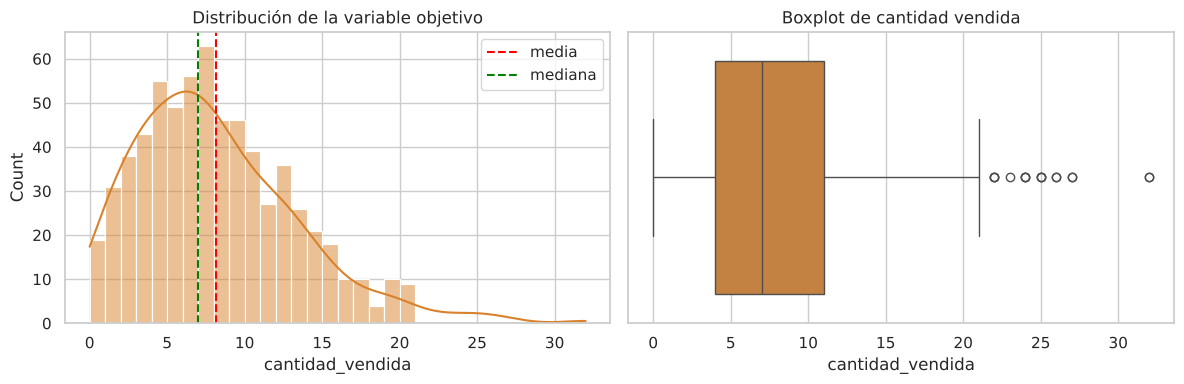

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['cantidad_vendida'], bins=range(0, 22), kde=True, ax=ax[0], color='#d9822b')
ax[0].axvline(df['cantidad_vendida'].mean(), color='red', ls='--', label='media')
ax[0].axvline(df['cantidad_vendida'].median(), color='green', ls='--', label='mediana')
ax[0].set_title('Distribución de la variable objetivo'); ax[0].legend()
sns.boxplot(x=df['cantidad_vendida'], ax=ax[1], color='#d9822b'); ax[1].set_title('Boxplot de cantidad vendida')
plt.tight_layout(); plt.show()

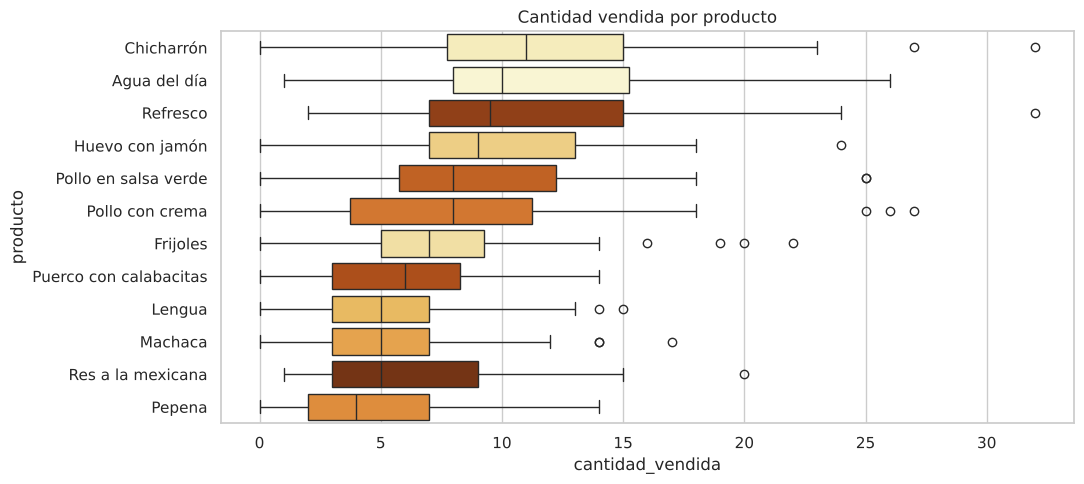

In [9]:
orden_prod = df.groupby('producto')['cantidad_vendida'].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, y='producto', x='cantidad_vendida', order=orden_prod, hue='producto', palette='YlOrBr', legend=False)
plt.title('Cantidad vendida por producto'); plt.tight_layout(); plt.show()

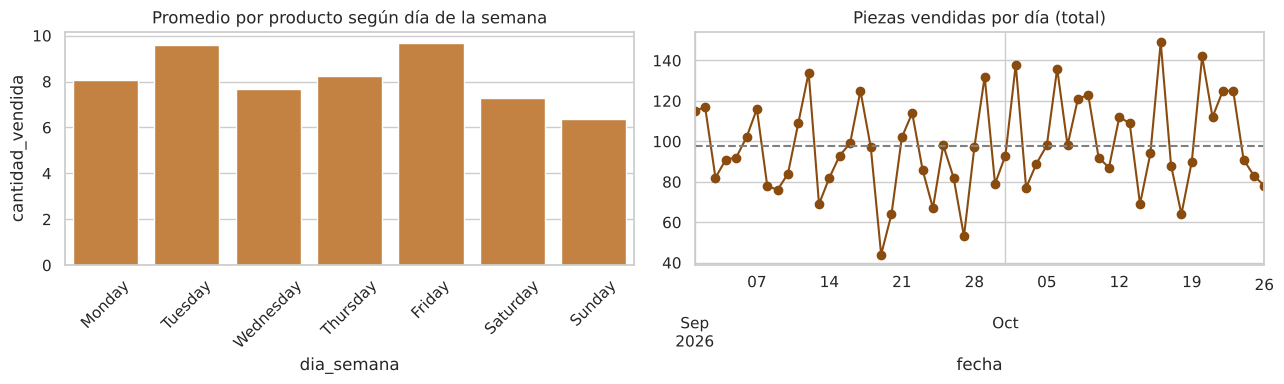

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x='dia_semana', y='cantidad_vendida', order=orden_dias, errorbar=None, ax=ax[0], color='#d9822b')
ax[0].set_title('Promedio por producto según día de la semana'); ax[0].tick_params(axis='x', rotation=45)
tot = df.groupby('fecha')['cantidad_vendida'].sum()
tot.plot(ax=ax[1], marker='o', color='#8a4b0f'); ax[1].set_title('Piezas vendidas por día (total)')
ax[1].axhline(tot.mean(), color='gray', ls='--')
plt.tight_layout(); plt.show()

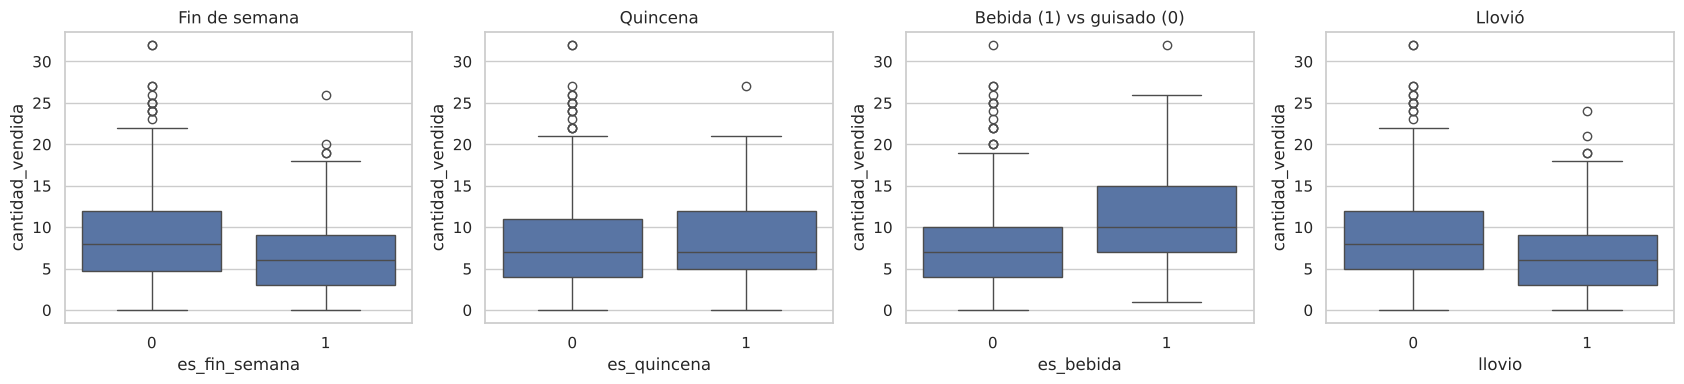

es_fin_semana   media(1)=6.83  media(0)=8.65  p-valor=0.000
es_quincena     media(1)=8.60  media(0)=8.06  p-valor=0.398
es_bebida       media(1)=11.31  media(0)=7.49  p-valor=0.000
llovio          media(1)=6.56  media(0)=8.56  p-valor=0.000


In [11]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
sns.boxplot(data=df, x='es_fin_semana', y='cantidad_vendida', ax=ax[0]); ax[0].set_title('Fin de semana')
sns.boxplot(data=df, x='es_quincena', y='cantidad_vendida', ax=ax[1]); ax[1].set_title('Quincena')
sns.boxplot(data=df, x='es_bebida', y='cantidad_vendida', ax=ax[2]); ax[2].set_title('Bebida (1) vs guisado (0)')
sns.boxplot(data=df, x='llovio', y='cantidad_vendida', ax=ax[3]); ax[3].set_title('Llovió')
plt.tight_layout(); plt.show()

# Pruebas simples de diferencia de medias (Welch)
for v in ['es_fin_semana','es_quincena','es_bebida','llovio']:
    a = df.loc[df[v]==1,'cantidad_vendida']; b = df.loc[df[v]==0,'cantidad_vendida']
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"{v:15s} media(1)={a.mean():.2f}  media(0)={b.mean():.2f}  p-valor={p:.3f}")

## 6. Matriz de correlación

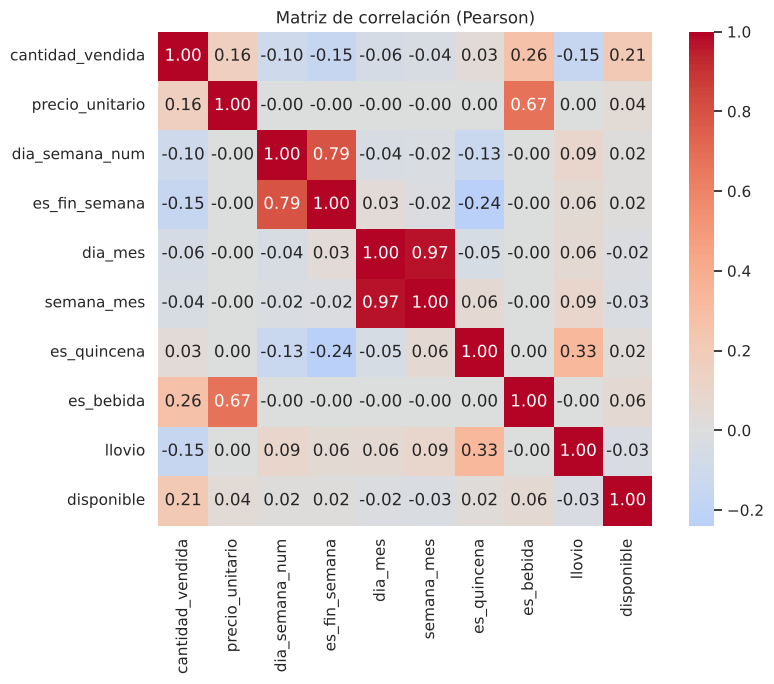

es_bebida          0.264
disponible         0.212
precio_unitario    0.160
es_fin_semana     -0.153
llovio            -0.152
dia_semana_num    -0.102
dia_mes           -0.058
semana_mes        -0.041
es_quincena        0.033
Name: cantidad_vendida, dtype: float64

In [12]:
corr_cols = ['cantidad_vendida','precio_unitario','dia_semana_num','es_fin_semana','dia_mes','semana_mes','es_quincena','es_bebida','llovio','disponible']
corr = df[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matriz de correlación (Pearson)'); plt.tight_layout(); plt.show()
corr['cantidad_vendida'].drop('cantidad_vendida').sort_values(key=abs, ascending=False).round(3)

**Cómo leerla:** la correlación de las variables de calendario con `cantidad_vendida` es la que indica si la fecha ayuda a predecir. Si es cercana a 0, el efecto del día es débil **a nivel de producto**, y el mayor poder explicativo vendrá del **tipo de producto** (que se codificará con *one-hot* al modelar). También conviene vigilar la multicolinealidad entre `precio_unitario` y `es_bebida`.

## 7. Valores nulos y atípicos

In [13]:
# Atípicos por producto con regla IQR (un atípico global puede ser normal para un producto popular)
def n_atipicos(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

atip = df.groupby('producto')['cantidad_vendida'].apply(n_atipicos).rename('atípicos_IQR')
z = df.groupby('producto')['cantidad_vendida'].transform(lambda s: (s - s.mean())/s.std())
atip_z = (z.abs() > 3).groupby(df['producto']).sum().rename('atípicos_|z|>3')
print(pd.concat([atip, atip_z], axis=1))
print('\nAtípicos globales IQR:', n_atipicos(df['cantidad_vendida']))

                        atípicos_IQR  atípicos_|z|>3
producto                                            
Agua del día                       0               0
Chicharrón                         2               1
Frijoles                           4               1
Huevo con jamón                    1               1
Lengua                             2               0
Machaca                            3               1
Pepena                             0               0
Pollo con crema                    3               0
Pollo en salsa verde               2               0
Puerco con calabacitas             0               0
Refresco                           1               1
Res a la mexicana                  1               1

Atípicos globales IQR: 16


In [14]:
# Los ceros: ¿en qué productos y días ocurren?
ceros = df[df['cantidad_vendida'] == 0]
print(ceros.groupby('producto').size())
print(ceros['dia_semana'].value_counts())

producto
Chicharrón                3
Frijoles                  1
Huevo con jamón           1
Lengua                    3
Machaca                   1
Pepena                    1
Pollo con crema           4
Pollo en salsa verde      1
Puerco con calabacitas    4
dtype: int64
dia_semana
Thursday     4
Tuesday      4
Monday       3
Saturday     3
Wednesday    3
Friday       1
Sunday       1
Name: count, dtype: int64


### Propuesta de tratamiento

| Hallazgo | Tratamiento propuesto |
|---|---|
| **Nulos** | No hay nulos en el archivo. Si aparecen al capturar datos reales: un día sin registro de un producto **no** se imputa con la media; se confirma con la dueña si no se vendió (0) o si faltó capturarlo. |
| **Ceros** | Son el caso a vigilar: un 0 puede significar *no hubo demanda* o *se acabó / no se cocinó ese guisado*. En el segundo caso la demanda real está **censurada** (fue mayor a 0). El dataset ya incluye `disponible`: los ceros con `disponible = 0` son faltantes por agotado (demanda censurada) y se excluyen o se tratan aparte; los demás son demanda baja real y se conservan. |
| **Atípicos (IQR / z-score)** | Se revisan **por producto**. Si no son errores de captura, se conservan: reflejan variación real de la demanda y quitarlos haría que el modelo subestime los días fuertes. Si hubiera valores imposibles (negativos, o muy superiores a la capacidad de cocina), se corrigen con la dueña. |
| **Escala / codificación** | `producto` y `dia_semana` → one-hot; variables numéricas → estandarizar solo para modelos sensibles a escala. |
| **Fuga de información** | `total_vendido` se **excluye** de las variables explicativas (es `cantidad × precio`). |


## 8. Conclusiones del EDA y siguientes pasos
1. Se define un problema de **regresión** sobre `cantidad_vendida` por producto y día, con valor práctico claro para las compras diarias.
2. El dataset está limpio (sin nulos, duplicados ni inconsistencias de total), pero **necesita ampliarse a ≥ 6 semanas** para cumplir los 500 registros.
3. **Hallazgo principal:** el tipo de producto es lo que más pesa (las bebidas se venden más: ≈10.9 vs ≈7.7 piezas, p < 0.001). Los factores de calendario son **débiles**: fin de semana (p ≈ 0.27) y quincena (p ≈ 0.29) no muestran diferencias significativas, y el patrón martes/jueves/viernes que contó la dueña solo se ve parcialmente (martes y viernes altos, jueves no). Con datos reales esto debe revisarse; con los sintéticos, el generador debería reflejar mejor esos efectos.
   - Atípicos: ninguno global; solo 3 por IQR en *Agua del día*, que se conservan.
   - Ceros: 12 registros (3.6 %), repartidos en 8 productos, a confirmar con la dueña.
4. Variable que aún falta y la dueña mencionó: **pedidos a domicilio**. Se propone incorporarla en el siguiente avance; con datos reales, `llovio` debería venir de una API de clima.
5. Siguiente avance: modelo base (promedio por producto), regresión lineal y un modelo de árboles, comparados con MAE/RMSE y validación respetando el orden temporal.
